# SeaDronesSee × DINOv3: tracking on two new clips

In this notebook I test if frozen DINOv3 features help a simple tracker keep the same ID on the same target. I use the ground truth boxes from the dataset, crop each box to 224×224 and take the DINOv3 CLS feature. I do not train anything, and I only use the GPU once to extract the features.

I look at two things:
1. whether keeping lost tracks longer and damping their velocity helps on the new clips
2. whether adding DINOv3 changes which boxes get linked, and whether those changes are correct

## How I run it on Kaggle
1. Import this notebook.
2. Add Input: **ubiratanfilho/sds-dataset**.
3. Set Accelerator to **GPU T4** and turn Internet on. Under Add-ons → Secrets, turn on **HF_TOKEN**.
4. Run All and download the result ZIP at the end.

## Clips
I use two clips with 50 images each, taking every 15th source frame:
- `sat0131`: NorthSea_Sat_DJI_0131.MP4, source frames 0 to 735
- `thu0109`: NorthSea_Thu_DJI_0109.MP4, source frames 2145 to 2880

I picked both clips from the annotation metadata before I ran any tracking.

## Six tracker settings
| Track management | Position and motion only | With DINOv3 |
|---|---|---|
| Keep a lost track for 2 frames, constant velocity | geometry_keep2 | dino224_keep2 |
| Keep a lost track for 4 frames, constant velocity | geometry_keep4 | dino224_keep4 |
| Keep a lost track for 4 frames, velocity damped by 0.5 per missed frame | geometry_damped_keep4 | dino224_damped_keep4 |

The position gate is 0.12 and the appearance weight is 0.55. Only geometry decides which matches are allowed. Among those, the tracker first makes as many matches as possible and then picks the lowest total cost. As a check, I also run the DINOv3 versions with the same feature for every box, which has to give exactly the geometry only result.

I extract the features for each clip once and all six settings share them. The features are saved after every batch.

## How I score it
The dataset has boxes but no IDs across frames, so I labelled the identities in thu0109 by hand. A link is two boxes in a row that get the same ID. I compare the tracker's links with the true links and compute precision, recall and F1.


## 1. Plan and settings
I keep the default values here. FEATURE_BATCH_SIZE only sets how many crops go through DINOv3 at once.


In [17]:
from pathlib import Path
import os, sys, json, io, re, zipfile, subprocess, importlib.util, hashlib, time, shutil
from importlib.metadata import version

# Settings for the tracking runs on the two new clips.
# The GPU is only used once to extract the frozen 224 CLS features.
SEQUENCE_PLAN = [
    {'name':'sat0131', 'video':'NorthSea_Sat_DJI_0131.MP4',
     'start_frame':0, 'n_frames':50, 'frame_step':15},
    {'name':'thu0109', 'video':'NorthSea_Thu_DJI_0109.MP4',
     'start_frame':2145, 'n_frames':50, 'frame_step':15},
]
DATA_ROOT = None
INPUT_ROOT = Path('/kaggle/input')
OUTPUT_BASE = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
FEATURE_BATCH_SIZE = 16       # use 8 if the GPU runs out of memory, finished batches are kept
MODEL_ID = 'facebook/dinov3-vits16-pretrain-lvd1689m'
MODEL_REVISION = 'main'       # pinned to one commit on the first run, both clips use the same weights
INPUT_SIZE = 224
APPEARANCE_WEIGHT = .55
MAX_CENTER_DISTANCE = .12
PLAYBACK_FPS = 5             # only for the comparison video
EXPORT_ANNOTATION_IMAGES = True
# Paths to my filled identity label files, None means no labels for that clip
GT_ID_FILES = {'sat0131': None, 'thu0109': '/kaggle/input/datasets/dzhang01jan/manual-label/identity_labels_template.csv'}
EXPECTED_ANNOTATION_HASHES = {
    'train':'5706b042f6b6c50267ed06076b8c27594ff4da76569edbd99ed53ed8bfa1db95',
    'val':'9e965c832263e6b9b9dd299637833e5b93924ecf9a1780b16fbd7c53e4a63f5e',
}
assert INPUT_SIZE==224 and isinstance(FEATURE_BATCH_SIZE,int) and FEATURE_BATCH_SIZE>0
assert len({p['name'] for p in SEQUENCE_PLAN})==len(SEQUENCE_PLAN)
for p in SEQUENCE_PLAN:
    assert re.fullmatch('[a-z0-9_]+',p['name'])
    assert isinstance(p['start_frame'],int) and p['start_frame']>=0
    assert isinstance(p['n_frames'],int) and 2<=p['n_frames']<=300
    assert p['frame_step']==15, 'I keep the sampling step at 15 source frames.'
missing=[pkg for module,pkg in {'numpy':'numpy','pandas':'pandas','scipy':'scipy',
                               'PIL':'pillow','packaging':'packaging'}.items()
         if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable,'-m','pip','install','-q',*missing],check=True)
import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageDraw, ImageFont
from IPython.display import display, FileLink, Video, Image as DisplayImage

VARIANTS = {
    'geometry_keep2': {'appearance_weight':0., 'max_missed':2, 'prediction_decay':1.},
    'dino224_keep2': {'appearance_weight':APPEARANCE_WEIGHT, 'max_missed':2, 'prediction_decay':1.},
    'geometry_keep4': {'appearance_weight':0., 'max_missed':4, 'prediction_decay':1.},
    'dino224_keep4': {'appearance_weight':APPEARANCE_WEIGHT, 'max_missed':4, 'prediction_decay':1.},
    'geometry_damped_keep4': {'appearance_weight':0., 'max_missed':4, 'prediction_decay':.5},
    'dino224_damped_keep4': {'appearance_weight':APPEARANCE_WEIGHT, 'max_missed':4, 'prediction_decay':.5},
}
print('Plan: two clips, six tracker settings, frozen DINOv3.')


Plan: two clips, six tracker settings, frozen DINOv3.


In [18]:
"""My simple tracker for known boxes.

Geometry decides which matches are allowed and appearance helps rank them.
Every setting first makes as many allowed matches as possible and then picks
the lowest total cost.
"""
from dataclasses import dataclass
import numpy as np
from scipy.optimize import linear_sum_assignment


def unit(x):
    x = np.asarray(x, dtype=np.float32)
    return x / np.maximum(np.linalg.norm(x, axis=-1, keepdims=True), 1e-12)


def state_of(box):
    return np.r_[(box[:2] + box[2:]) / 2, box[2:] - box[:2]]


def box_of(state):
    size = np.maximum(state[2:], 1e-6)
    return np.r_[state[:2] - size / 2, state[:2] + size / 2]


def iou_matrix(a, b):
    lo = np.maximum(a[:, None, :2], b[None, :, :2])
    hi = np.minimum(a[:, None, 2:], b[None, :, 2:])
    overlap = np.maximum(hi - lo, 0).prod(-1)
    aa = np.maximum(a[:, 2:] - a[:, :2], 0).prod(-1)
    ab = np.maximum(b[:, 2:] - b[:, :2], 0).prod(-1)
    return overlap / np.maximum(aa[:, None] + ab[None, :] - overlap, 1e-12)


def gated_assignment(cost, valid):
    """Make as many allowed matches as possible, then pick the lowest total cost.

    Leaving out a real match costs two penalties, which is more than all real
    edges together, so the solver always keeps the most matches. Edges outside
    the gate are never picked.
    """
    cost, valid = np.asarray(cost, float), np.asarray(valid, bool)
    n, m = cost.shape
    if valid.shape != cost.shape:
        raise ValueError('Gate and cost shapes differ')
    if not n or not m or not valid.any():
        return []
    if not np.isfinite(cost[valid]).all() or np.any(cost[valid] < 0):
        raise ValueError('Valid costs must be finite and nonnegative')
    penalty = (min(n, m) + 1) * max(1., float(cost[valid].max()))
    huge = (n + m + 1) * penalty * 10
    matrix = np.full((n + m, n + m), huge)
    matrix[:n, :m] = np.where(valid, cost, huge)
    matrix[np.arange(n), m + np.arange(n)] = penalty
    matrix[n + np.arange(m), np.arange(m)] = penalty
    matrix[n:, m:] = 0
    rr, cc = linear_sum_assignment(matrix)
    return [(int(r), int(c)) for r, c in zip(rr, cc)
            if r < n and c < m and valid[r, c]]


def prediction_factor(missed, decay):
    # Average velocity factor over the frames a track has missed.
    # Example: 3 missed frames and decay=.5 give mean(1,.5,.25,.125)=.46875.
    # My clips always use a step of 15 source frames.
    return float(np.mean(decay ** np.arange(missed + 1)))


@dataclass
class Track:
    identity: int
    state: np.ndarray
    velocity: np.ndarray
    timestamp: float
    feature: np.ndarray | None
    missed: int = 0


class AssociationTracker:
    def __init__(self, appearance_weight=0., max_center_distance=.12, max_missed=2, prediction_decay=1.):
        if not 0 <= appearance_weight <= 1 or max_center_distance <= 0 or max_missed < 0:
            raise ValueError('Invalid tracker configuration')
        if not 0 < prediction_decay <= 1:
            raise ValueError('prediction_decay must be in (0,1]')
        self.prediction_decay = float(prediction_decay)
        self.alpha = float(appearance_weight)
        self.gate = float(max_center_distance)
        self.max_missed = int(max_missed)
        self.tracks, self.next_identity, self.last_timestamp = [], 1, None

    def update(self, boxes, timestamp, features=None):
        boxes = np.asarray(boxes, float).reshape(-1, 4)
        timestamp = float(timestamp)
        if not np.isfinite(timestamp) or (self.last_timestamp is not None and timestamp <= self.last_timestamp):
            raise ValueError('Source-frame timestamps must increase strictly')
        if not np.isfinite(boxes).all() or np.any(boxes[:, 2:] <= boxes[:, :2]):
            raise ValueError('Invalid xyxy boxes')
        if self.alpha:
            features = np.asarray(features, np.float32)
            if (features.ndim != 2 or len(features) != len(boxes) or
                    not np.isfinite(features).all() or
                    np.any(np.linalg.norm(features, axis=1) < 1e-8)):
                raise ValueError('Need one finite nonzero feature per box')
            features = unit(features)
        self.last_timestamp = timestamp
        predicted = np.array([box_of(t.state + t.velocity * (timestamp - t.timestamp) * prediction_factor(t.missed, self.prediction_decay))
                              for t in self.tracks]).reshape(-1, 4)
        matches = []
        if len(predicted) and len(boxes):
            ca, cb = (predicted[:, :2] + predicted[:, 2:]) / 2, (boxes[:, :2] + boxes[:, 2:]) / 2
            distance = np.linalg.norm(ca[:, None] - cb[None, :], axis=-1)
            spatial = .65 * (1 - iou_matrix(predicted, boxes)) + .35 * np.minimum(distance / self.gate, 1)
            valid = distance <= self.gate
            cost = spatial.copy()
            if self.alpha:
                appearance = (1 - np.clip(np.stack([t.feature for t in self.tracks]) @ features.T, -1, 1)) / 2
                # I add the appearance cost on top, so identical features give the geometry only result.
                cost += self.alpha * appearance
            matches = gated_assignment(cost, valid)
        ids = np.zeros(len(boxes), dtype=int)
        matched_tracks, matched_boxes = set(), set()
        for ti, di in matches:
            t = self.tracks[ti]
            observation = state_of(boxes[di])
            velocity = (observation - t.state) / (timestamp - t.timestamp)
            velocity[2:] = 0
            t.velocity = .5 * t.velocity + .5 * velocity
            t.state, t.timestamp, t.missed = observation, timestamp, 0
            if self.alpha:
                t.feature = unit(.8 * t.feature + .2 * features[di])
            ids[di] = t.identity
            matched_tracks.add(ti)
            matched_boxes.add(di)
        for ti, t in enumerate(self.tracks):
            if ti not in matched_tracks:
                t.missed += 1
        self.tracks = [t for t in self.tracks if t.missed <= self.max_missed]
        for di, box in enumerate(boxes):
            if di not in matched_boxes:
                self.tracks.append(Track(self.next_identity, state_of(box), np.zeros(4),
                                         timestamp, features[di].copy() if self.alpha else None))
                ids[di] = self.next_identity
                self.next_identity += 1
        return ids

"""Helpers for picking the frames, saving and loading the feature cache, and scoring identities."""
from pathlib import Path
from collections import defaultdict
import hashlib, json, os, io
import numpy as np
import pandas as pd


def canonical(value):
    return json.dumps(value,sort_keys=True,ensure_ascii=False,separators=(',',':'))


def digest(value):
    return hashlib.sha256(canonical(value).encode()).hexdigest()[:20]


def hash_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda:handle.read(1024*1024),b''):
            h.update(chunk)
    return h.hexdigest()


def walk_inputs(base):
    seen=set()
    for current,dirs,files in os.walk(base,followlinks=True):
        real=Path(current).resolve()
        if real in seen:
            dirs[:]=[]
            continue
        seen.add(real)
        dirs[:]=sorted(d for d in dirs if d not in {'images','.git','__pycache__'})
        yield Path(current),files


def discover_root(input_root,override,expected_hashes):
    roots=[]
    for p,files in walk_inputs(Path(override) if override else input_root):
        if p.name!='annotations' or 'instances_train.json' not in files:
            continue
        root=p.parent
        if not (root/'images').is_dir() or not (p/'instances_val.json').is_file():
            continue
        hashes={s:hash_file(p/f'instances_{s}.json') for s in ['train','val']}
        if expected_hashes is None or hashes==expected_hashes:
            roots.append((root.resolve(),hashes))
    unique={str(p):(p,h) for p,h in roots}
    roots=[unique[k] for k in sorted(unique)]
    if not roots:
        raise FileNotFoundError('Could not find SeaDronesSee with the expected annotations. Add '
            'ubiratanfilho/sds-dataset as an Input, or set DATA_ROOT to the folder with images/ and annotations/.')
    if len(roots)>1:
        print('Found more than one copy of the same annotations, using:',roots[0][0])
    return roots[0]


def read_groups(root):
    groups=defaultdict(list)
    for split in ['train','val']:
        data=json.loads((Path(root)/'annotations'/f'instances_{split}.json').read_text())
        annotations=defaultdict(list)
        for a in data['annotations']:
            if a.get('category_id',0)!=0 and not a.get('iscrowd',0):
                annotations[a['image_id']].append(a)
        for im in data['images']:
            source=im.get('source') or {}
            v,t=source.get('video'),source.get('frame_no')
            if not v or not isinstance(t,(int,float)) or not np.isfinite(t) or int(t)!=t:
                continue
            groups[v].append({'source_video':v,'source_frame':int(t),'image_id':int(im['id']),
                'file_name':im['file_name'],'split':split,'width':int(im['width']),
                'height':int(im['height']),'source_folder':source.get('folder_name'),
                'path':str(Path(root)/'images'/split/im['file_name']),
                'annotations':sorted(annotations[im['id']],key=lambda a:a['id'])})
    return groups


def select_context(groups,plan):
    video=plan['video']
    if video not in groups:
        raise ValueError(f'Video not found: {video}. Available videos: {sorted(groups)}')
    rows=groups[video]
    folders={r['source_folder'] for r in rows if r['source_folder']}
    if len(folders)>1:
        raise ValueError(f'{video} comes from more than one source folder.')
    by_time=defaultdict(list)
    for r in rows:by_time[r['source_frame']].append(r)
    requested=[plan['start_frame']+i*plan['frame_step'] for i in range(plan['n_frames'])]
    missing=[t for t in requested if len(by_time[t])!=1]
    if missing:
        raise ValueError(f'{video}: these frames are missing or duplicated: {missing[:8]}')
    frames=[];boxes=[];observations=[];skipped=[]
    for i,t in enumerate(requested):
        original=by_time[t][0]
        frame={k:v for k,v in original.items() if k!='annotations'}
        frame['sample_index']=i
        frames.append(frame)
        detections=[]
        for ann in original['annotations']:
            raw=np.asarray(ann['bbox'],float)
            if raw.shape!=(4,) or not np.isfinite(raw).all():
                raise ValueError('Nonfinite or malformed annotation bbox')
            x,y,w,h=raw
            box=np.array([x,y,x+w,y+h])
            box[[0,2]]=np.clip(box[[0,2]],0,frame['width'])
            box[[1,3]]=np.clip(box[[1,3]],0,frame['height'])
            if box[2]-box[0]<1 or box[3]-box[1]<1:
                skipped.append({'image_id':frame['image_id'],'annotation_id':ann['id'],'reason':'degenerate_after_clipping'})
                continue
            j=len(detections)
            detections.append({'xyxy':box.tolist(),'annotation_id':int(ann['id'])})
            observations.append({'obs_id':f'{plan["name"]}:{frame["split"]}:{frame["image_id"]}:{ann["id"]}',
                'sequence':plan['name'],'frame_box_key':f'f{i:03d}_d{j:03d}',
                'sample_index':i,'sample_number':i+1,'box_index':j,'source_frame':t,
                'image_id':frame['image_id'],'annotation_id':int(ann['id']),
                'category_id':int(ann['category_id']), # kept for reference, the tracker does not use it
                'x1':box[0],'y1':box[1],'x2':box[2],'y2':box[3],
                'original_area':float((box[2]-box[0])*(box[3]-box[1]))})
        boxes.append(detections)
    if len({(f['width'],f['height']) for f in frames})!=1:
        raise ValueError('Sequence image dimensions vary; inspect source before tracking.')
    if not observations:
        raise ValueError('Selected sequence has no valid target boxes')
    obs=pd.DataFrame(observations)
    if not obs.obs_id.is_unique:
        raise ValueError('Duplicate observation identifiers')
    return {'name':plan['name'],'plan':plan,'frames':frames,'boxes':boxes,'obs':obs,'skipped':skipped}


def read_feature_cache(source,protocol,obs_ids):
    with np.load(source,allow_pickle=False) as z:
        if z['protocol'].item()!=canonical(protocol) or z['obs_ids'].tolist()!=list(obs_ids):
            raise ValueError('Cache protocol or observation order differs')
        features,done=z['features'].copy(),z['done'].copy()
        meta=json.loads(z['metadata'].item())
    if features.shape!=(len(obs_ids),384) or features.dtype!=np.float32 or done.shape!=(len(obs_ids),) or done.dtype!=bool:
        raise ValueError('Invalid cache dimensions or dtype')
    if not np.isfinite(features[done]).all() or not np.allclose(np.linalg.norm(features[done],axis=1),1,atol=1e-4):
        raise ValueError('Invalid completed feature values')
    if done.any() and not meta.get('model_commit'):
        raise ValueError('Completed cache has no pinned model revision')
    return features,done,meta


def write_feature_cache(path,protocol,obs_ids,features,done,metadata):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_suffix('.tmp')
    with temporary.open('wb') as handle:
        np.savez_compressed(handle,protocol=canonical(protocol),obs_ids=np.asarray(obs_ids,dtype=str),
                            features=features,done=done,metadata=json.dumps(metadata,ensure_ascii=False))
    os.replace(temporary,path)


def run_variant(ctx,spec,feature_array,center_gate):
    # AssociationTracker is defined above in this cell.
    tracker=AssociationTracker(max_center_distance=center_gate,**spec)
    identities=[];offset=0
    for f,ds in zip(ctx['frames'],ctx['boxes']):
        pixels=np.asarray([d['xyxy'] for d in ds],float).reshape(-1,4)
        normalized=pixels/np.array([f['width'],f['height']]*2)
        ff=feature_array[offset:offset+len(ds)] if spec['appearance_weight'] else None
        offset+=len(ds)
        identities.extend(tracker.update(normalized,f['source_frame'],ff).tolist())
    return np.asarray(identities,dtype=int)


def trajectory_links(obs,ids):
    last={};edges=set()
    for key,identity in zip(obs.obs_id,ids):
        identity=str(identity)
        if identity in last:edges.add((last[identity],key))
        last[identity]=key
    return edges


def score_identities(ctx,labels,results):
    obs=ctx['obs']
    if not {'obs_id','gt_id'}.issubset(labels.columns):
        raise ValueError('The label file needs obs_id and gt_id columns')
    labels=labels[['obs_id','gt_id']].copy()
    if labels.obs_id.duplicated().any() or set(labels.obs_id)!=set(obs.obs_id):
        raise ValueError(f'{ctx["name"]}: the label file must have every obs_id of this clip exactly once')
    if labels.gt_id.isna().any() or labels.gt_id.astype(str).str.strip().eq('').any():
        raise ValueError('Some gt_id values are still empty')
    labels['gt_id']=labels.gt_id.astype(str).str.strip()
    ordered=obs.merge(labels,on='obs_id',validate='one_to_one',sort=False)
    if ordered.duplicated(['sample_index','gt_id']).any():
        raise ValueError('Two boxes in the same frame have the same gt_id')
    truth=trajectory_links(obs,ordered.gt_id.to_numpy())
    frame_of=obs.set_index('obs_id').sample_index.to_dict()
    def gaps(edges):return {e for e in edges if frame_of[e[1]]-frame_of[e[0]]>1}
    true_gaps=gaps(truth)
    rows=[]
    for name,ids in results.items():
        pred=trajectory_links(obs,ids)
        tp,fp,fn=len(pred&truth),len(pred-truth),len(truth-pred)
        rows.append({'sequence':ctx['name'],'method':name,'correct_links':tp,'wrong_links':fp,
            'missing_true_links':fn,'link_precision':tp/(tp+fp) if tp+fp else np.nan,
            'link_recall':tp/(tp+fn) if tp+fn else np.nan,
            'link_f1':2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan,
            'true_gap_links':len(true_gaps),'correct_gap_links':len(pred&true_gaps),
            'wrong_gap_links':len(gaps(pred)-truth),'missing_true_gap_links':len(true_gaps-pred)})
    return pd.DataFrame(rows)


## 2. Tracker and data tools
The tracker uses the same matching rules and velocity damping as my last run. I keep the class labels as metadata, the tracker does not use them.


## 3. Load the clips and check the data
I check the annotation version, the frame numbers, the image sizes and the image file hashes. If a frame is missing, the notebook stops. I save the plan before running anything.


In [19]:
root,annotation_hashes=discover_root(INPUT_ROOT,DATA_ROOT,EXPECTED_ANNOTATION_HASHES)
groups=read_groups(root)
contexts=[select_context(groups,p) for p in SEQUENCE_PLAN]
plan_record={'dataset':'ubiratanfilho/sds-dataset','annotation_hashes':annotation_hashes,
             'sequence_plan':SEQUENCE_PLAN,'variants':VARIANTS,
             'center_gate':MAX_CENTER_DISTANCE,'feature_size':INPUT_SIZE,
             'model_id':MODEL_ID,'requested_revision':MODEL_REVISION,'version':1}
experiment_key=digest(plan_record)
OUT=OUTPUT_BASE/'seadronessee_mot_newvideos'/experiment_key
CACHE_DIR=OUTPUT_BASE/'seadronessee_mot_feature_cache'
OUT.mkdir(parents=True,exist_ok=True);CACHE_DIR.mkdir(parents=True,exist_ok=True)
(OUT/'experiment_plan.json').write_text(json.dumps(plan_record,indent=2,ensure_ascii=False),encoding='utf-8')
overview=[]
for ctx in contexts:
    ctx['out']=OUT/ctx['name'];ctx['out'].mkdir(exist_ok=True)
    for f in ctx['frames']:
        path=Path(f['path'])
        if not path.is_file():raise FileNotFoundError(f'Missing image: {path}')
        f['image_sha256']=hash_file(path)
        with Image.open(path) as image:
            if image.size!=(f['width'],f['height']):raise ValueError(f'Image size does not match: {path}')
            image.verify()
    # I leave out the mount paths so the cache still works if the Kaggle input path changes.
    selection=[{k:v for k,v in f.items() if k!='path'} for f in ctx['frames']]
    ctx['protocol']={'model_id':MODEL_ID,'requested_revision':MODEL_REVISION,
        'precision':'float32_no_autocast','input_size':INPUT_SIZE,
        'crop':'floor_ceil_tight_xyxy_bicubic_pad_rgb124_116_104',
        'features':'pooler_output_L2','annotation_hashes':annotation_hashes,
        'selection':selection,'boxes':ctx['boxes'],'version':1}
    ctx['cache_name']='features224_'+digest(ctx['protocol'])+'.npz'
    ctx['cache_path']=CACHE_DIR/ctx['cache_name']
    ctx['features']=np.full((len(ctx['obs']),384),np.nan,dtype=np.float32)
    ctx['done']=np.zeros(len(ctx['obs']),dtype=bool)
    ctx['metadata']={}
    ctx['obs'].to_csv(ctx['out']/'observations.csv',index=False)
    pd.DataFrame(selection).to_csv(ctx['out']/'selected_frames.csv',index=False)
    pd.DataFrame(ctx['skipped'],columns=['image_id','annotation_id','reason']).to_csv(ctx['out']/'skipped_boxes.csv',index=False)
    labels=ctx['obs'].copy();labels['gt_id']=''
    labels.to_csv(ctx['out']/'identity_labels_template.csv',index=False)
    area=ctx['obs'].original_area
    overview.append({'sequence':ctx['name'],'video':ctx['plan']['video'],
        'first_source_frame':ctx['frames'][0]['source_frame'],'last_source_frame':ctx['frames'][-1]['source_frame'],
        'frames':len(ctx['frames']),'observations':len(area),'small':int((area<32**2).sum()),
        'medium':int(((area>=32**2)&(area<96**2)).sum()),'large':int((area>=96**2).sum())})
overview=pd.DataFrame(overview)
overview.to_csv(OUT/'sequence_overview.csv',index=False)
display(overview)
print('Total boxes:',int(overview.observations.sum()))
print('All six settings use the same boxes, images and features.')


,sequence,video,first_source_frame,last_source_frame,frames,observations,small,medium,large
0,sat0131,NorthSea_Sat_DJI_0131.MP4,0,735,50,390,84,156,150
1,thu0109,NorthSea_Thu_DJI_0109.MP4,2145,2880,50,150,0,150,0


Total boxes: 540
All six settings use the same boxes, images and features.


## 4. Load cached features
I can load features from the current output folder, an old output folder, or the result ZIP of this notebook (SeaDronesSee_MOT_NewVideos_Results*.zip). I only use a cache if the images, boxes, model settings and box order all match, and I never mix features from different model commits.


In [20]:
def save_context_cache(ctx):
    write_feature_cache(ctx['cache_path'],ctx['protocol'],ctx['obs'].obs_id,
                        ctx['features'],ctx['done'],ctx['metadata'])

def accept_cache(ctx,source,label):
    try:
        features,done,metadata=read_feature_cache(source,ctx['protocol'],ctx['obs'].obs_id)
    except Exception as exc:
        print('Skipping a cache that does not match:',label,type(exc).__name__)
        return
    if done.sum()>ctx['done'].sum():
        ctx['features'],ctx['done'],ctx['metadata']=features,done,metadata
        print(ctx['name'],'loaded',int(done.sum()),'/',len(done),'features from',label)

cache_lookup={ctx['cache_name']:ctx for ctx in contexts}
for ctx in contexts:
    if ctx['cache_path'].is_file():accept_cache(ctx,ctx['cache_path'],'current output')
for directory,files in walk_inputs(INPUT_ROOT):
    for name in files:
        if name in cache_lookup:
            accept_cache(cache_lookup[name],directory/name,str(directory/name))
        elif name.startswith('SeaDronesSee_MOT_NewVideos_Results') and name.lower().endswith('.zip'):
            with zipfile.ZipFile(directory/name) as archive:
                for member in archive.namelist():
                    basename=Path(member).name
                    if basename in cache_lookup:
                        ctx=cache_lookup[basename]
                        if archive.getinfo(member).file_size > 16*len(ctx['obs'])*384+2_000_000:
                            raise ValueError('Unexpectedly large feature-cache member')
                        accept_cache(ctx,io.BytesIO(archive.read(member)),name+' / '+member)
commits={ctx['metadata']['model_commit'] for ctx in contexts if ctx['done'].any()}
if len(commits)>1:
    raise RuntimeError('Found caches from different model commits. Only attach results from one run.')
PINNED_COMMIT=next(iter(commits),None)
for ctx in contexts:
    if ctx['done'].any():save_context_cache(ctx)
remaining=sum(int((~ctx['done']).sum()) for ctx in contexts)
print('Features left to extract:',remaining)


sat0131 loaded 390 / 390 features from current output
thu0109 loaded 150 / 150 features from current output
Features left to extract: 0


## 5. Extract the 224 CLS features once on the GPU
I use the same model commit for both clips. I crop each box from the original image and pad it to 224×224, keeping its shape. I turn off the extra resize in the processor and check the real input size.

No weights are trained here. Every batch is saved to /kaggle/working/seadronessee_mot_feature_cache. If the GPU runs out of memory, I set FEATURE_BATCH_SIZE to 8 and run this cell again, and finished batches are skipped. I download the checkpoint before I stop a session, because Kaggle does not keep the working folder.


In [21]:
from functools import lru_cache
context_lookup={ctx['name']:ctx for ctx in contexts}

@lru_cache(maxsize=4)
def load_rgb(sequence,sample_index):
    ctx=context_lookup[sequence]
    with Image.open(ctx['frames'][sample_index]['path']) as handle:
        return handle.convert('RGB')

def object_crop(ctx,index):
    row=ctx['obs'].iloc[int(index)]
    image=load_rgb(ctx['name'],int(row.sample_index))
    crop=image.crop((int(np.floor(row.x1)),int(np.floor(row.y1)),
                    int(np.ceil(row.x2)),int(np.ceil(row.y2))))
    return ImageOps.pad(crop,(INPUT_SIZE,INPUT_SIZE),method=Image.Resampling.BICUBIC,
                        color=(124,116,104),centering=(.5,.5))

remaining=sum(int((~ctx['done']).sum()) for ctx in contexts)
if remaining:
    token=os.environ.get('HF_TOKEN','').strip()
    if not token:
        try:
            from kaggle_secrets import UserSecretsClient
            token=(UserSecretsClient().get_secret('HF_TOKEN') or '').strip()
        except Exception:token=''
    if not token:
        raise RuntimeError('HF_TOKEN not found. Turn it on under Add-ons → Secrets, '
                           'then run this cell again.')
    if importlib.util.find_spec('torch') is None:
        raise RuntimeError('This needs a Kaggle GPU environment with PyTorch.')
    from packaging.version import Version
    if importlib.util.find_spec('transformers') is None or Version(version('transformers'))<Version('4.56'):
        subprocess.run([sys.executable,'-m','pip','install','-q','transformers>=4.56,<6'],check=True)
    import torch
    from transformers import AutoImageProcessor, AutoModel
    from huggingface_hub import hf_hub_download
    if not torch.cuda.is_available():
        raise RuntimeError('Some features still need to be extracted, so this needs the GPU.')
    requested=PINNED_COMMIT or MODEL_REVISION
    try:
        config_path=Path(hf_hub_download(MODEL_ID,'config.json',revision=requested,token=token))
        parts=config_path.parts
        resolved=parts[parts.index('snapshots')+1]
        processor=AutoImageProcessor.from_pretrained(MODEL_ID,revision=resolved,token=token)
        model=AutoModel.from_pretrained(MODEL_ID,revision=resolved,token=token).to(device='cuda',dtype=torch.float32).eval()
    except Exception as exc:
        raise RuntimeError('Could not load DINOv3. Check that Internet is on, HF_TOKEN is enabled '
            'and the Hugging Face account has access to the model. Error: '+type(exc).__name__) from None
    for p in model.parameters():p.requires_grad_(False)
    torch.backends.cuda.matmul.allow_tf32=False
    current_meta={'model_id':MODEL_ID,'model_commit':resolved,'torch':torch.__version__,
        'transformers':version('transformers'),'pillow':version('pillow'),
        'processor':processor.to_dict(),'precision':'float32_no_autocast',
        'device':torch.cuda.get_device_name(0)}
    for ctx in contexts:
        if ctx['done'].any() and not ctx['done'].all():
            old=ctx['metadata']
            for key in ['model_commit','torch','transformers','pillow','precision']:
                if old.get(key)!=current_meta[key]:
                    del model,processor
                    torch.cuda.empty_cache()
                    raise RuntimeError(f'The partial cache has a different {key} from this environment. '
                                       'Resume in the same environment or start a new cache.')
    try:
        for ctx in contexts:
            if ctx['done'].all():continue
            ctx['metadata']=current_meta.copy()
            todo=np.flatnonzero(~ctx['done'])
            started=time.perf_counter()
            save_context_cache(ctx)
            for start in range(0,len(todo),FEATURE_BATCH_SIZE):
                indices=todo[start:start+FEATURE_BATCH_SIZE]
                crops=[object_crop(ctx,int(i)) for i in indices]
                inputs=processor(images=crops,do_resize=False,do_center_crop=False,return_tensors='pt').to('cuda')
                if tuple(inputs['pixel_values'].shape[-2:])!=(224,224):
                    raise RuntimeError('Actual model input is not 224x224')
                with torch.inference_mode():output=model(**inputs)
                features=unit(output.pooler_output.float().cpu().numpy())
                if features.shape!=(len(indices),384) or not np.isfinite(features).all():
                    raise RuntimeError('Invalid CLS features')
                ctx['features'][indices]=features
                ctx['done'][indices]=True
                save_context_cache(ctx)
                if start==0 or (start//FEATURE_BATCH_SIZE+1)%10==0 or ctx['done'].all():
                    print(ctx['name'],f'{int(ctx["done"].sum())}/{len(ctx["done"])} saved')
            print(ctx['name'],'extraction time, including loading and saving:',round(time.perf_counter()-started,1),'s')
    finally:
        del model,processor
        torch.cuda.empty_cache()
        load_rgb.cache_clear()
else:
    print('All features are already cached.')
assert all(ctx['done'].all() for ctx in contexts)
print('Features are ready.')


All features are already cached.
Features are ready.


## 6. Run the six settings and three constant feature checks
I start a new tracker for each clip. This cell saves the tracks and counts which links change when I add DINOv3.


In [22]:
all_summary=[];all_changes=[];all_effects=[];control_rows=[]
for ctx in contexts:
    results={name:run_variant(ctx,spec,ctx['features'],MAX_CENTER_DISTANCE)
             for name,spec in VARIANTS.items()}
    constant=np.zeros_like(ctx['features']);constant[:,0]=1
    for suffix in ['keep2','keep4','damped_keep4']:
        control=run_variant(ctx,VARIANTS['dino224_'+suffix],constant,MAX_CENTER_DISTANCE)
        assert np.array_equal(control,results['geometry_'+suffix]), 'The constant feature check failed.'
        control_rows.append({'sequence':ctx['name'],'setting':suffix,'constant_equals_geometry':True})
        a=trajectory_links(ctx['obs'],results['geometry_'+suffix])
        b=trajectory_links(ctx['obs'],results['dino224_'+suffix])
        all_effects.append({'sequence':ctx['name'],'setting':suffix,'links_changed_by_dino':len(a^b)})
        for edges,kind in [(b-a,'added_by_appearance'),(a-b,'removed_by_appearance')]:
            all_changes.extend({'sequence':ctx['name'],'comparison':'appearance_'+suffix,
                'previous_obs':x,'current_obs':y,'change':kind} for x,y in sorted(edges))
    ctx['results']=results
    baseline=trajectory_links(ctx['obs'],results['dino224_keep2'])
    records=[]
    for method,ids in results.items():
        counts=pd.Series(ids).value_counts()
        edges=trajectory_links(ctx['obs'],ids)
        row={'sequence':ctx['name'],'method':method,'observations':len(ids),'created_ids':len(counts),
            'single_observation_tracks':int((counts==1).sum()),
            'added_links_vs_dino_keep2':len(edges-baseline),'removed_links_vs_dino_keep2':len(baseline-edges)}
        all_summary.append(row)
        table=ctx['obs'].copy();table['method'],table['track_id']=method,ids;records.append(table)
        if method in ['dino224_keep4','dino224_damped_keep4']:
            for changed_edges,kind in [(edges-baseline,'added'),(baseline-edges,'removed')]:
                all_changes.extend({'sequence':ctx['name'],'comparison':method+'_vs_dino_keep2',
                    'previous_obs':x,'current_obs':y,'change':kind} for x,y in sorted(changed_edges))
    pd.concat(records,ignore_index=True).to_csv(ctx['out']/'tracking_predictions.csv',index=False)
summary=pd.DataFrame(all_summary)
summary.to_csv(OUT/'descriptive_summary.csv',index=False)
effects=pd.DataFrame(all_effects)
effects.to_csv(OUT/'appearance_contribution.csv',index=False)
pd.DataFrame(control_rows).to_csv(OUT/'constant_feature_controls.csv',index=False)
pd.DataFrame(all_changes,columns=['sequence','comparison','previous_obs','current_obs','change']).to_csv(OUT/'changed_links.csv',index=False)
display(summary)
display(effects)
print('All constant feature checks passed.')
print('Next I score these links with my manual labels.')


,sequence,method,observations,created_ids,single_observation_tracks,added_links_vs_dino_keep2,removed_links_vs_dino_keep2
0,sat0131,geometry_keep2,390,9,0,0,0
1,sat0131,dino224_keep2,390,9,0,0,0
2,sat0131,geometry_keep4,390,9,0,0,0
3,sat0131,dino224_keep4,390,9,0,0,0
4,sat0131,geometry_damped_keep4,390,9,0,0,0
5,sat0131,dino224_damped_keep4,390,9,0,0,0
6,thu0109,geometry_keep2,150,8,0,2,2
7,thu0109,dino224_keep2,150,8,0,0,0
8,thu0109,geometry_keep4,150,8,0,2,2
9,thu0109,dino224_keep4,150,8,0,0,0


,sequence,setting,links_changed_by_dino
0,sat0131,keep2,0
1,sat0131,keep4,0
2,sat0131,damped_keep4,0
3,thu0109,keep2,4
4,thu0109,keep4,4
5,thu0109,damped_keep4,4


All constant feature checks passed.
Next I score these links with my manual labels.


## 7. Score with my manual identity labels
Each clip has an identity_labels_template.csv. To label a clip, I open annotation_frames/fNNN.jpg, where dNNN is the box index that matches frame_box_key in the template, and I give the same gt_id to the same target in every frame. Then I upload the filled file as an Input and put its path in GT_ID_FILES. Clips without labels are skipped.


In [23]:
(OUT/'identity_link_metrics.csv').unlink(missing_ok=True)
scored=[]
for ctx in contexts:
    label_path=GT_ID_FILES.get(ctx['name'])
    if not label_path:
        print(ctx['name'],': no labels, skipping scoring.')
        continue
    labels=pd.read_csv(label_path,dtype={'obs_id':str,'gt_id':str})
    scored.append(score_identities(ctx,labels,ctx['results']))
if scored:
    identity_metrics=pd.concat(scored,ignore_index=True)
    identity_metrics.to_csv(OUT/'identity_link_metrics.csv',index=False)
    display(identity_metrics)
    print('Link precision, recall and F1 for the labelled clips.')


sat0131 : no labels, skipping scoring.


,sequence,method,correct_links,wrong_links,missing_true_links,link_precision,link_recall,link_f1,true_gap_links,correct_gap_links,wrong_gap_links,missing_true_gap_links
0,thu0109,geometry_keep2,136,6,11,0.957746,0.925170,0.941176,0,0,0,0
1,thu0109,dino224_keep2,138,4,9,0.971831,0.938776,0.955017,0,0,0,0
2,thu0109,geometry_keep4,136,6,11,0.957746,0.925170,0.941176,0,0,0,0
3,thu0109,dino224_keep4,138,4,9,0.971831,0.938776,0.955017,0,0,0,0
4,thu0109,geometry_damped_keep4,136,6,11,0.957746,0.925170,0.941176,0,0,0,0
5,thu0109,dino224_damped_keep4,138,4,9,0.971831,0.938776,0.955017,0,0,0,0


Link precision, recall and F1 for the labelled clips.


## 8. Six panel video and labelling frames
Top row: geometry only. Bottom row: with DINOv3. Columns: keep2, keep4, keep4 with damping. Each panel numbers its own IDs, so I check whether an ID stays on the same target. The playback speed is only for viewing.


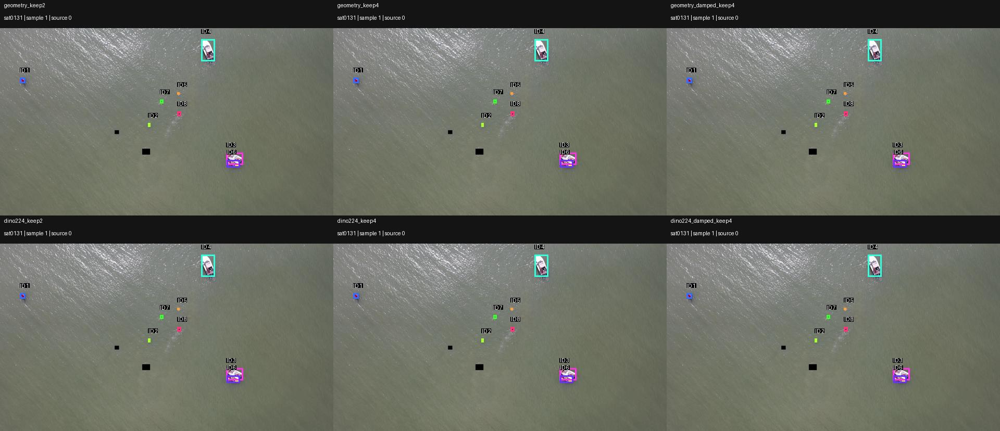

sat0131 video and labelling frames done.


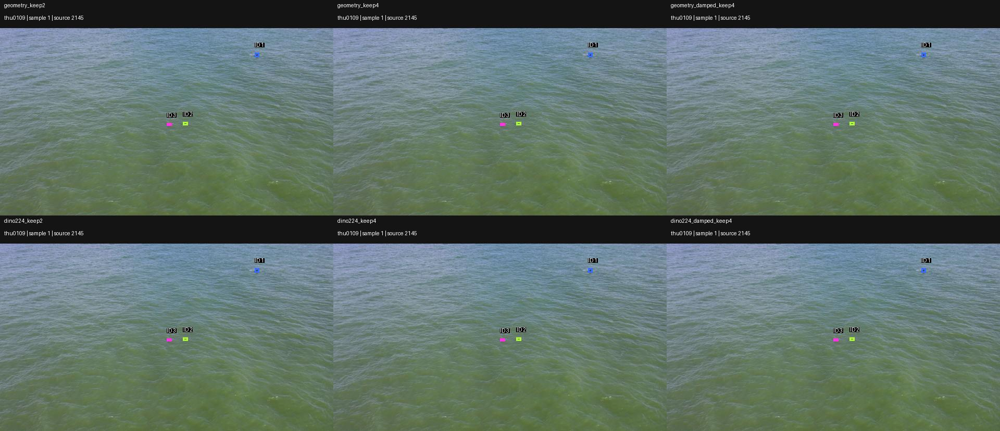

thu0109 video and labelling frames done.


In [24]:
import colorsys
try:font=ImageFont.truetype('DejaVuSans.ttf',17)
except OSError:font=ImageFont.load_default()

def identity_color(identity):
    return tuple(round(255*v) for v in colorsys.hsv_to_rgb((int(identity)*.61803398875)%1,.8,1))

def draw_panel(image,ctx,index,method,width):
    h=round(image.height*width/image.width);h+=h%2
    panel=Image.new('RGB',(width,h+54),(20,20,20))
    panel.paste(image.resize((width,h)),(0,54))
    draw=ImageDraw.Draw(panel)
    draw.text((8,4),method or 'Box indices for labelling',fill='white',font=font)
    draw.text((8,28),f'{ctx["name"]} | sample {index+1} | source {ctx["frames"][index]["source_frame"]}',fill='white',font=font)
    sx,sy=width/image.width,h/image.height
    for row_index,row in ctx['obs'][ctx['obs'].sample_index==index].iterrows():
        identity=int(ctx['results'][method][row_index]) if method else int(row.box_index)
        label=f'ID {identity}' if method else f'd{int(row.box_index):03d}'
        rect=(row.x1*sx,row.y1*sy+54,row.x2*sx,row.y2*sy+54)
        draw.rectangle(rect,outline=identity_color(identity),width=3)
        pos=(max(0,min(rect[0],width-95)),max(54,rect[1]-21))
        draw.rectangle(draw.textbbox(pos,label,font=font),fill='black')
        draw.text(pos,label,fill='white',font=font)
    return panel

GRID_METHODS=[['geometry_keep2','geometry_keep4','geometry_damped_keep4'],
              ['dino224_keep2','dino224_keep4','dino224_damped_keep4']]

def render_comparison(ctx,index):
    image=load_rgb(ctx['name'],index)
    panels=[draw_panel(image,ctx,index,method,640) for row in GRID_METHODS for method in row]
    w,h=panels[0].size
    canvas=Image.new('RGB',(3*w,2*h))
    for k,panel in enumerate(panels):canvas.paste(panel,((k%3)*w,(k//3)*h))
    return canvas

for ctx in contexts:
    for stale in ['tracking_comparison.mp4','video_export.log']:(ctx['out']/stale).unlink(missing_ok=True)
    first=render_comparison(ctx,0)
    first.save(ctx['out']/'preview_first_frame.jpg')
    display(DisplayImage(filename=str(ctx['out']/'preview_first_frame.jpg')))
    if shutil.which('ffmpeg'):
        path=ctx['out']/'tracking_comparison.mp4'
        with (ctx['out']/'video_export.log').open('wb') as log:
            encoder=subprocess.Popen(['ffmpeg','-y','-loglevel','error','-f','rawvideo','-pix_fmt','rgb24',
                '-s',f'{first.width}x{first.height}','-r',str(PLAYBACK_FPS),'-i','pipe:0','-an',
                '-c:v','libx264','-pix_fmt','yuv420p','-movflags','+faststart',str(path)],stdin=subprocess.PIPE,stderr=log)
            try:
                for i in range(len(ctx['frames'])):encoder.stdin.write(render_comparison(ctx,i).tobytes())
                encoder.stdin.close();code=encoder.wait()
            except Exception:
                encoder.kill();encoder.wait();raise
        if code:print('Video export failed, see',ctx['out']/'video_export.log')
        else:display(Video(str(path),embed=True,width=1100))
    else:print('ffmpeg not found, saving only the preview and labelling frames.')
    if EXPORT_ANNOTATION_IMAGES:
        folder=ctx['out']/'annotation_frames';folder.mkdir(exist_ok=True)
        for i in range(len(ctx['frames'])):
            draw_panel(load_rgb(ctx['name'],i),ctx,i,None,1600).save(folder/f'f{i:03d}.jpg',quality=93)
    print(ctx['name'],'video and labelling frames done.')
load_rgb.cache_clear()


## 9. Save the results
This cell zips everything. Next time I can add the ZIP as an Input and the features load from it without unzipping. The dataset still needs to be attached.


In [25]:
cache_output=OUT/'feature_cache';cache_output.mkdir(exist_ok=True)
for ctx in contexts:
    save_context_cache(ctx)
    shutil.copy2(ctx['cache_path'],cache_output/ctx['cache_name'])
configuration={**plan_record,'root_used':str(root),'versions':{k:version(k) for k in ['numpy','pandas','scipy','pillow']},
    'feature_metadata':{ctx['name']:ctx['metadata'] for ctx in contexts},
    'notes':['I use the ground truth boxes, no detector','DINOv3 is frozen, I do not train anything',
        'I rebuilt the clips from the detection set metadata',
        'I only score clips that I labelled by hand',
        'The labels are only used for scoring','I do not compensate for camera motion']}
(OUT/'run_config.json').write_text(json.dumps(configuration,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
(OUT/'README.txt').write_text(
    'Tracking on two new SeaDronesSee clips. I use the ground truth boxes and frozen DINOv3 224 CLS features. Nothing is trained.\n'
    'descriptive_summary.csv: number of IDs and changed links for each setting.\n'
    'appearance_contribution.csv: how many links change when I add DINOv3.\n'
    'changed_links.csv: every link that changes, by track management or by appearance.\n'
    'identity_link_metrics.csv: link precision, recall and F1 for the labelled clips.\n'
    'Video: top row geometry only, bottom row with DINOv3. Columns: keep2, keep4, keep4 with damping.\n'
    'Labelling: in annotation_frames/fNNN.jpg, dNNN matches frame_box_key in the template. '
    'I give the same gt_id to the same target in every frame, starting from 1 in each clip.\n'
    'obs_id is the key for each box.\n'
    'To score a clip, I upload the filled file, set GT_ID_FILES and run the scoring and saving cells again.\n'
    'To reuse the features, I add this ZIP as an Input. The dataset still needs to be attached.\n',encoding='utf-8')
archive=shutil.make_archive(str(OUTPUT_BASE/f'SeaDronesSee_MOT_NewVideos_Results_{experiment_key}'),'zip',OUT)
print('Done. Download the result ZIP below.')
display(FileLink(archive))


Done. Download the result ZIP below.


/kaggle/working/SeaDronesSee_MOT_NewVideos_Results_eaafa4cd8dfb3eda3339.zip

In [26]:
from pathlib import Path
import json, hashlib, os, shutil, zipfile
import numpy as np
import pandas as pd
from IPython.display import display, FileLink

required = [
    "AssociationTracker",
    "trajectory_links",
    "score_identities",
]
assert all(k in globals() for k in required), (
    "Run the settings cell and the tracker cell first."
)

RESULT_ZIP = None  # after a restart, put the full path to the result ZIP here

if "contexts" in globals():
    C = next(c for c in contexts if c["name"] == "thu0109")
else:
    files = (
        [Path(RESULT_ZIP)]
        if RESULT_ZIP
        else list(Path("/kaggle/input").rglob(
            "SeaDronesSee_MOT_NewVideos_Results*.zip"
        ))
    )
    assert len(files) == 1, (
        "Add the result ZIP as an Input and set RESULT_ZIP."
    )

    archive_key = hashlib.sha256(files[0].read_bytes()).hexdigest()[:16]
    restored = Path("/kaggle/working/mot_identity_source") / archive_key

    with zipfile.ZipFile(files[0]) as z:
        for name in z.namelist():
            assert (restored / name).resolve().is_relative_to(
                restored.resolve()
            ), "Bad path in the ZIP"
        z.extractall(restored)

    roots = [
        p.parent
        for p in restored.rglob("run_config.json")
        if (p.parent / "thu0109/observations.csv").is_file()
    ]
    assert len(roots) == 1

    base = roots[0]
    folder = base / "thu0109"
    obs = pd.read_csv(folder / "observations.csv")
    frames = pd.read_csv(
        folder / "selected_frames.csv"
    ).to_dict("records")
    pred = pd.read_csv(folder / "tracking_predictions.csv")

    C = dict(name="thu0109", out=folder, obs=obs, frames=frames)
    C["results"] = {
        method: group.set_index("obs_id").loc[
            obs.obs_id, "track_id"
        ].to_numpy()
        for method, group in pred.groupby("method")
    }

    caches = []
    for path in (base / "feature_cache").glob("*.npz"):
        with np.load(path, allow_pickle=False) as z:
            if z["obs_ids"].tolist() == obs.obs_id.tolist():
                assert z["done"].all()
                caches.append(z["features"].copy())

    assert len(caches) == 1, "Feature cache is missing or duplicated"
    C["features"] = caches[0]

O = C["obs"].reset_index(drop=True).copy()

assert len(O) == 150 and len(C["frames"]) == 50
assert O.obs_id.is_unique
assert O.equals(
    O.sort_values(["sample_index", "box_index"]).reset_index(drop=True)
)
assert [f["source_frame"] for f in C["frames"]] == list(
    range(2145, 2881, 15)
)
assert C["features"].shape == (150, 384)
assert np.isfinite(C["features"]).all()

# Keep a copy of the six original predictions so the next runs do not overwrite them.
BASE = {
    method: np.asarray(ids).copy()
    for method, ids in C["results"].items()
}
assert len(BASE) == 6
assert all(len(ids) == 150 for ids in BASE.values())

REVIEW_DIR = Path(C["out"]) / "identity_review"
REVIEW_DIR.mkdir(exist_ok=True)
LABEL_FILE = REVIEW_DIR / "identity_labels.csv"

# After a restart, put the path to an uploaded review sheet here.
IMPORT_LABELS = None

source = (
    LABEL_FILE if LABEL_FILE.exists()
    else Path(IMPORT_LABELS) if IMPORT_LABELS
    else None
)

if source:
    L = pd.read_csv(source, dtype=str, keep_default_na=False)
    assert L.obs_id.is_unique and set(L.obs_id) == set(O.obs_id)
    L = L.set_index("obs_id").loc[O.obs_id].reset_index()
    assert {"gt_id", "confirmed"}.issubset(L.columns)
    L["confirmed"] = L.confirmed.str.lower().eq("true")
else:
    L = O[
        ["obs_id", "frame_box_key", "sample_index",
         "sample_number", "box_index"]
    ].copy()
    L["gt_id"] = ""
    L["confirmed"] = False

def save_labels():
    temporary = LABEL_FILE.with_suffix(".tmp")
    L.to_csv(temporary, index=False, encoding="utf-8-sig")
    os.replace(temporary, LABEL_FILE)

save_labels()
print("Loaded the cached features and the six original predictions.")
print("Confirmed:", int(L.confirmed.sum()), "/150")

Loaded the cached features and the six original predictions.
Confirmed: 0 /150


In [27]:
from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd
from IPython.display import display, FileLink

required = ["C", "O", "BASE", "AssociationTracker"]
missing = [name for name in required if name not in globals()]
assert not missing, f"Run the previous cell first. Missing: {missing}"

assert C["name"] == "thu0109"
assert len(O) == 150 and len(C["frames"]) == 50
assert O.obs_id.is_unique
assert O.equals(
    O.sort_values(["sample_index", "box_index"]).reset_index(drop=True)
)

FEATURES = np.asarray(C["features"])
assert FEATURES.shape == (150, 384)
assert np.isfinite(FEATURES).all()

# My own link counter for this part, so it does not clash with trajectory_links.
def auto_links(ids):
    last = {}
    edges = set()

    for obs_id, identity in zip(O.obs_id, ids):
        identity = int(identity)
        if identity in last:
            edges.add((last[identity], obs_id))
        last[identity] = obs_id

    return edges


class AutoLastPositionTracker(AssociationTracker):
    def update(self, boxes, timestamp, features=None):
        # Use the last seen position instead of moving the track by its velocity.
        # Everything else works like AssociationTracker.
        for track in self.tracks:
            track.velocity[:] = 0
        return super().update(boxes, timestamp, features)


def run_auto_trial(motion, gate, alpha, constant=False):
    tracker_class = (
        AssociationTracker
        if motion == "cv"
        else AutoLastPositionTracker
    )

    tracker = tracker_class(
        appearance_weight=alpha,
        max_center_distance=gate,
        max_missed=2,
    )

    features = FEATURES

    # Constant feature check: every box gets the same feature.
    if constant:
        features = np.zeros_like(FEATURES)
        features[:, 0] = 1

    ids = []

    for sample_index, frame in enumerate(C["frames"]):
        rows = O[O.sample_index == sample_index]

        boxes = rows[["x1", "y1", "x2", "y2"]].to_numpy(float)
        boxes = boxes / np.array(
            [frame["width"], frame["height"]] * 2
        )

        frame_features = (
            features[rows.index] if alpha else None
        )

        frame_ids = tracker.update(
            boxes,
            frame["source_frame"],
            frame_features,
        )
        ids.extend(frame_ids)

    return np.asarray(ids, dtype=int)


# First I check that I get the two original keep2 results back.
assert np.array_equal(
    run_auto_trial("cv", 0.12, 0.0),
    BASE["geometry_keep2"],
), "Could not reproduce the geometry keep2 result."

assert np.array_equal(
    run_auto_trial("cv", 0.12, 0.55),
    BASE["dino224_keep2"],
), "Could not reproduce the DINOv3 keep2 result."

print("Both keep2 results reproduced.")

SETTINGS = [
    ("cv",      0.12),
    ("lastpos", 0.12),
    ("cv",      0.16),
    ("lastpos", 0.16),
]

DEV = {}
SPECS = []
CONTROLS = []

for motion, gate in SETTINGS:
    setting = f"{motion}_gate{round(gate * 100)}"

    for kind, alpha in [
        ("geometry", 0.0),
        ("dino", 0.55),
    ]:
        method = f"{setting}_{kind}"

        DEV[method] = run_auto_trial(
            motion=motion,
            gate=gate,
            alpha=alpha,
        )

        SPECS.append({
            "method": method,
            "motion": motion,
            "center_gate": gate,
            "appearance_weight": alpha,
            "max_missed": 2,
        })

    constant_ids = run_auto_trial(
        motion=motion,
        gate=gate,
        alpha=0.55,
        constant=True,
    )

    passed = np.array_equal(
        constant_ids,
        DEV[f"{setting}_geometry"],
    )
    assert passed, f"Constant feature check failed for {setting}."

    CONTROLS.append({
        "setting": setting,
        "constant_equals_geometry": bool(passed),
    })

print("Ran 8 settings, all 4 constant feature checks passed.")
print("cv = constant velocity, lastpos = last seen position.")

Both keep2 results reproduced.
Ran 8 settings, all 4 constant feature checks passed.
cv = constant velocity, lastpos = last seen position.


In [28]:
AUTO_DIR = Path(C["out"]) / "automatic_comparison"
AUTO_DIR.mkdir(parents=True, exist_ok=True)

summary_rows = []
prediction_tables = []
changed_rows = []
appearance_rows = []

lookup = O.set_index("obs_id")

for method, ids in DEV.items():
    counts = pd.Series(ids).value_counts()
    edges = auto_links(ids)

    # Compare with the original geometry or DINOv3 keep2 result.
    baseline_name = (
        "geometry_keep2"
        if method.endswith("_geometry")
        else "dino224_keep2"
    )
    baseline_edges = auto_links(BASE[baseline_name])

    added = edges - baseline_edges
    removed = baseline_edges - edges

    summary_rows.append({
        "method": method,
        "created_ids": len(counts),
        "single_observation_tracks": int((counts == 1).sum()),
        "total_links": len(edges),
        "added_links_vs_original": len(added),
        "removed_links_vs_original": len(removed),
    })

    prediction_tables.append(
        O.assign(method=method, track_id=ids)
    )

    for change, changed_edges in [
        ("added", added),
        ("removed", removed),
    ]:
        for previous_obs, current_obs in sorted(changed_edges):
            changed_rows.append({
                "method": method,
                "baseline": baseline_name,
                "change": change,
                "previous_obs": previous_obs,
                "current_obs": current_obs,
                "previous_box": lookup.loc[
                    previous_obs, "frame_box_key"
                ],
                "current_box": lookup.loc[
                    current_obs, "frame_box_key"
                ],
            })

# For each motion model and gate, which links change when I add DINOv3?
for motion, gate in SETTINGS:
    setting = f"{motion}_gate{round(gate * 100)}"

    geometry_edges = auto_links(DEV[f"{setting}_geometry"])
    dino_edges = auto_links(DEV[f"{setting}_dino"])

    appearance_rows.append({
        "setting": setting,
        "added_by_dino": len(dino_edges - geometry_edges),
        "removed_by_dino": len(geometry_edges - dino_edges),
        "links_changed_by_dino": len(
            geometry_edges ^ dino_edges
        ),
    })

automatic_summary = pd.DataFrame(summary_rows)
appearance_summary = pd.DataFrame(appearance_rows)

changed_columns = [
    "method", "baseline", "change",
    "previous_obs", "current_obs",
    "previous_box", "current_box",
]
changed_links = pd.DataFrame(
    changed_rows, columns=changed_columns
)

print("IDs and links for each method:")
display(automatic_summary)

print("Links changed by DINOv3:")
display(appearance_summary)

automatic_summary.to_csv(
    AUTO_DIR / "automatic_summary.csv",
    index=False,
)
appearance_summary.to_csv(
    AUTO_DIR / "appearance_contribution.csv",
    index=False,
)
changed_links.to_csv(
    AUTO_DIR / "changed_links.csv",
    index=False,
)
pd.concat(prediction_tables, ignore_index=True).to_csv(
    AUTO_DIR / "tracking_predictions.csv",
    index=False,
)
pd.DataFrame(SPECS).to_csv(
    AUTO_DIR / "experiment_settings.csv",
    index=False,
)
pd.DataFrame(CONTROLS).to_csv(
    AUTO_DIR / "constant_feature_controls.csv",
    index=False,
)

protocol = {
    "sequence": "thu0109",
    "frames": 50,
    "observations": 150,
    "input_size": 224,
    "feature_dimension": 384,
    "feature_source": "existing cached DINOv3 features",
    "training": False,
    "manual_identities_used": False,
    "baseline_replay_passed": True,
    "constant_feature_controls_passed": 4,
    "experiment_type": "development comparison",
    # The gate is used both to pick candidates and to scale the distance cost.
    "gate_also_normalizes_distance_cost": True,
    "notes": [
        "I use the ground truth boxes",
        "This cell counts IDs and changed links, the scores come in the next cell",
        "I do not compensate for camera motion",
    ],
}

(AUTO_DIR / "experiment_protocol.json").write_text(
    json.dumps(protocol, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

archive = shutil.make_archive(
    str(Path(C["out"]) / "thu0109_automatic_comparison"),
    "zip",
    AUTO_DIR,
)

print("Done. Download the ZIP below.")
display(FileLink(archive))

IDs and links for each method:


,method,created_ids,single_observation_tracks,total_links,added_links_vs_original,removed_links_vs_original
0,cv_gate12_geometry,8,0,142,0,0
1,cv_gate12_dino,8,0,142,0,0
2,lastpos_gate12_geometry,8,0,142,9,9
3,lastpos_gate12_dino,8,0,142,7,7
4,cv_gate16_geometry,3,0,147,9,4
5,cv_gate16_dino,3,0,147,7,2
6,lastpos_gate16_geometry,4,0,146,12,8
7,lastpos_gate16_dino,4,0,146,10,6


Links changed by DINOv3:


,setting,added_by_dino,removed_by_dino,links_changed_by_dino
0,cv_gate12,2,2,4
1,lastpos_gate12,0,0,0
2,cv_gate16,0,0,0
3,lastpos_gate16,0,0,0


Done. Download the ZIP below.


/kaggle/working/seadronessee_mot_newvideos/eaafa4cd8dfb3eda3339/thu0109/thu0109_automatic_comparison.zip

In [29]:
# 10. Score the eight settings with my manual labels
# The labels are only used for scoring. Run the settings cell, the tracker cell
# and the three cells above first.
LABEL_PATH = GT_ID_FILES.get("thu0109")
assert LABEL_PATH, "Set the thu0109 label file in GT_ID_FILES first."

labels = pd.read_csv(LABEL_PATH, dtype={"obs_id": str, "gt_id": str})
dev_scores = score_identities({"name": "thu0109", "obs": O}, labels, DEV)
dev_scores.insert(2, "created_ids", [len(set(DEV[m])) for m in dev_scores.method])

# Check every link DINOv3 added or removed against the labels.
gt = labels.set_index("obs_id").loc[O.obs_id, "gt_id"].str.strip().to_numpy()
truth = trajectory_links(O, gt)
box = O.set_index("obs_id").frame_box_key

dino_rows = []
for motion, gate in SETTINGS:
    setting = f"{motion}_gate{round(gate * 100)}"
    g = trajectory_links(O, DEV[f"{setting}_geometry"])
    d = trajectory_links(O, DEV[f"{setting}_dino"])
    dino_rows.append({
        "setting": setting,
        "added_by_dino": len(d - g),
        "added_correct": len((d - g) & truth),
        "removed_by_dino": len(g - d),
        "removed_were_wrong": len((g - d) - truth),
    })
dino_check = pd.DataFrame(dino_rows)

# Wrong links and missed true links left in each method.
error_rows = []
for method, ids in DEV.items():
    pred = trajectory_links(O, ids)
    for kind, edges in [("wrong_link", pred - truth), ("missing_true_link", truth - pred)]:
        for a, b in sorted(edges):
            error_rows.append({"method": method, "type": kind,
                               "previous_box": box[a], "current_box": box[b]})
link_errors = pd.DataFrame(error_rows, columns=["method", "type", "previous_box", "current_box"])

print("True links:", len(truth))
display(dev_scores[["method", "created_ids", "correct_links", "wrong_links",
                    "missing_true_links", "link_precision", "link_recall", "link_f1"]].round(3))
display(dino_check)
wrong = link_errors[link_errors.type == "wrong_link"]
print("Wrong links left in each method (full list in link_errors.csv):")
display((wrong.previous_box + "→" + wrong.current_box)
        .groupby(wrong.method, sort=False).agg(", ".join).to_frame("wrong_links"))

dev_scores.to_csv(AUTO_DIR / "identity_link_metrics.csv", index=False)
dino_check.to_csv(AUTO_DIR / "dino_changes_checked.csv", index=False)
link_errors.to_csv(AUTO_DIR / "link_errors.csv", index=False)

# Update the protocol file, now that I scored with my labels.
protocol_path = AUTO_DIR / "experiment_protocol.json"
protocol = json.loads(protocol_path.read_text(encoding="utf-8"))
protocol["manual_identities_used"] = "only for scoring"
protocol["identity_labels"] = str(LABEL_PATH)
protocol["true_links"] = len(truth)
protocol["notes"] = [
    x for x in protocol["notes"] if not x.startswith("This cell counts")
] + [
    "Link precision, recall and F1 come from my manual labels",
    "I added gate 0.16 and the last position model after looking at thu0109",
]
protocol_path.write_text(json.dumps(protocol, ensure_ascii=False, indent=2), encoding="utf-8")

# Zip again so the scores are in the ZIP too.
archive = shutil.make_archive(str(Path(C["out"]) / "thu0109_automatic_comparison"), "zip", AUTO_DIR)
print("Done. Download the ZIP below.")
display(FileLink(archive))


True links: 147


,method,created_ids,correct_links,wrong_links,missing_true_links,link_precision,link_recall,link_f1
0,cv_gate12_geometry,8,136,6,11,0.958,0.925,0.941
1,cv_gate12_dino,8,138,4,9,0.972,0.939,0.955
2,lastpos_gate12_geometry,8,134,8,13,0.944,0.912,0.927
3,lastpos_gate12_dino,8,134,8,13,0.944,0.912,0.927
4,cv_gate16_geometry,3,145,2,2,0.986,0.986,0.986
5,cv_gate16_dino,3,145,2,2,0.986,0.986,0.986
6,lastpos_gate16_geometry,4,140,6,7,0.959,0.952,0.956
7,lastpos_gate16_dino,4,140,6,7,0.959,0.952,0.956


,setting,added_by_dino,added_correct,removed_by_dino,removed_were_wrong
0,cv_gate12,2,2,2,2
1,lastpos_gate12,0,0,0,0
2,cv_gate16,0,0,0,0
3,lastpos_gate16,0,0,0,0


Wrong links left in each method (full list in link_errors.csv):


,wrong_links
method,
cv_gate12_geometry,"f005_d001→f006_d002, f005_d002→f006_d001, f012..."
cv_gate12_dino,"f005_d001→f006_d002, f005_d002→f006_d001, f012..."
lastpos_gate12_geometry,"f005_d001→f006_d002, f005_d002→f006_d001, f007..."
lastpos_gate12_dino,"f005_d001→f006_d002, f005_d002→f006_d001, f007..."
cv_gate16_geometry,"f005_d001→f006_d002, f005_d002→f006_d001"
cv_gate16_dino,"f005_d001→f006_d002, f005_d002→f006_d001"
lastpos_gate16_geometry,"f005_d001→f006_d002, f005_d002→f006_d001, f007..."
lastpos_gate16_dino,"f005_d001→f006_d002, f005_d002→f006_d001, f007..."


Done. Download the ZIP below.


/kaggle/working/seadronessee_mot_newvideos/eaafa4cd8dfb3eda3339/thu0109/thu0109_automatic_comparison.zip